In [18]:

import pandas as pd

url = "https://raw.githubusercontent.com/propublica/compas-analysis/master/compas-scores-two-years.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())


Dataset loaded successfully!
Dataset shape: (7214, 53)


,id,name,first,last,compas_screening_date,sex,dob,age,age_cat,race,...,v_decile_score,v_score_text,v_screening_date,in_custody,out_custody,priors_count.1,start,end,event,two_year_recid
0,1,miguel hernandez,miguel,hernandez,2013-08-14,Male,1947-04-18,69,Greater than 45,Other,...,1,Low,2013-08-14,2014-07-07,2014-07-14,0,0,327,0,0
1,3,kevon dixon,kevon,dixon,2013-01-27,Male,1982-01-22,34,25 - 45,African-American,...,1,Low,2013-01-27,2013-01-26,2013-02-05,0,9,159,1,1
2,4,ed philo,ed,philo,2013-04-14,Male,1991-05-14,24,Less than 25,African-American,...,3,Low,2013-04-14,2013-06-16,2013-06-16,4,0,63,0,1
3,5,marcu brown,marcu,brown,2013-01-13,Male,1993-01-21,23,Less than 25,African-American,...,6,Medium,2013-01-13,NaN,NaN,1,0,1174,0,0
4,6,bouthy pierrelouis,bouthy,pierrelouis,2013-03-26,Male,1973-01-22,43,25 - 45,Other,...,1,Low,2013-03-26,NaN,NaN,2,0,1102,0,0


In [19]:

# Check column names and data types
print("Columns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
display(
    df.isnull().sum()
      .sort_values(ascending=False)
      .head(15)
)

# Check target variables
print("\nDecile score distribution:")
print(df["decile_score"].value_counts().sort_index())

print("\nRecidivism distribution:")
print(df["is_recid"].value_counts(dropna=False))

print("\nTwo-year recidivism distribution:")
print(df["two_year_recid"].value_counts(dropna=False))


Columns:
['id', 'name', 'first', 'last', 'compas_screening_date', 'sex', 'dob', 'age', 'age_cat', 'race', 'juv_fel_count', 'decile_score', 'juv_misd_count', 'juv_other_count', 'priors_count', 'days_b_screening_arrest', 'c_jail_in', 'c_jail_out', 'c_case_number', 'c_offense_date', 'c_arrest_date', 'c_days_from_compas', 'c_charge_degree', 'c_charge_desc', 'is_recid', 'r_case_number', 'r_charge_degree', 'r_days_from_arrest', 'r_offense_date', 'r_charge_desc', 'r_jail_in', 'r_jail_out', 'violent_recid', 'is_violent_recid', 'vr_case_number', 'vr_charge_degree', 'vr_offense_date', 'vr_charge_desc', 'type_of_assessment', 'decile_score.1', 'score_text', 'screening_date', 'v_type_of_assessment', 'v_decile_score', 'v_score_text', 'v_screening_date', 'in_custody', 'out_custody', 'priors_count.1', 'start', 'end', 'event', 'two_year_recid']

Data types:
id                           int64
name                        object
first                       object
last                        object
compas_

violent_recid              7214
vr_charge_degree           6395
vr_offense_date            6395
vr_case_number             6395
vr_charge_desc             6395
c_arrest_date              6077
r_jail_in                  4898
r_days_from_arrest         4898
r_jail_out                 4898
r_charge_desc              3801
r_case_number              3743
r_charge_degree            3743
r_offense_date             3743
c_offense_date             1159
days_b_screening_arrest     307
dtype: int64


Decile score distribution:
decile_score
1     1440
2      941
3      747
4      769
5      681
6      641
7      592
8      512
9      508
10     383
Name: count, dtype: int64

Recidivism distribution:
is_recid
0    3743
1    3471
Name: count, dtype: int64

Two-year recidivism distribution:
two_year_recid
0    3963
1    3251
Name: count, dtype: int64


In [20]:

# Display duplicated column names
duplicate_cols = df.columns[df.columns.duplicated()].tolist()
print("Duplicate column names:", duplicate_cols)

# Keep the first occurrence of each column name
df = df.loc[:, ~df.columns.duplicated()].copy()

print("Shape after removing duplicate columns:", df.shape)
print("Unique column names:", df.columns.is_unique)


Duplicate column names: []
Shape after removing duplicate columns: (7214, 53)
Unique column names: True


In [21]:

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score

# Ensure the two targets are available
required = ["decile_score", "is_recid"]
missing = [c for c in required if c not in df.columns]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

# Convert targets to numeric and retain valid outcomes
df["decile_score"] = pd.to_numeric(df["decile_score"], errors="coerce")
df["is_recid"] = pd.to_numeric(df["is_recid"], errors="coerce")

data = df[
    df["decile_score"].between(1, 10)
    & df["is_recid"].isin([0, 1])
].copy()

# Predictors available in the COMPAS dataset
candidate_features = [
    "age", "sex", "race", "age_cat",
    "juv_fel_count", "juv_misd_count",
    "juv_other_count", "priors_count",
    "c_charge_degree"
]

features = [c for c in candidate_features if c in data.columns]

X = data[features].copy()
y_linear = data["decile_score"].astype(float)
y_logistic = data["is_recid"].astype(int)

# Identify numerical and categorical features
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = [
    c for c in X.columns if c not in numeric_features
]

# Impute missing values, scale numerical features,
# and one-hot encode categorical features
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Split indices so both models use exactly the same records
indices = np.arange(len(data))
train_idx, test_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=40,
    stratify=y_logistic
)

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
yA_train, yA_test = y_linear.iloc[train_idx], y_linear.iloc[test_idx]
yB_train, yB_test = y_logistic.iloc[train_idx], y_logistic.iloc[test_idx]

# PREPROCESSING DOCUMENTATION AND OUTLIER CHECK

print("1. Dataset dimensions:", data.shape)
print("2. Training rows:", len(X_train))
print("3. Testing rows:", len(X_test))
print("4. Random seed: 40")

print("\n5. Missing values in raw predictors:")
display(X.isnull().sum().to_frame("Missing count"))

print("\n6. Numerical feature summary:")
display(X[numeric_features].describe().T)

# IQR-based outlier diagnostic; does not delete observations
outlier_rows = []

for col in numeric_features:
    series = X[col].dropna()

    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = ((series < lower) | (series > upper)).sum()

    outlier_rows.append({
        "Feature": col,
        "IQR lower bound": lower,
        "IQR upper bound": upper,
        "Outlier count": int(count),
        "Outlier percentage": 100 * count / len(series)
    })

outlier_table = pd.DataFrame(outlier_rows)
display(outlier_table.round(3))

outlier_table.to_csv(
    "compas_outlier_diagnostics.csv", index=False
)

print("\nPreprocessing decisions:")
print("- Missing numerical values: training-set median imputation.")
print("- Missing categorical values: training-set mode imputation.")
print("- Numerical predictors: StandardScaler.")
print("- Categorical predictors: one-hot encoding.")
print("- Outliers: identified using the 1.5 x IQR rule.")
print("- Outliers are retained unless a documented data error is found.")
print("- Preprocessing is fitted on training data through the pipeline.")

print("Features used:", features)
print("Eligible records:", len(data))
print("Training rows:", len(train_idx))
print("Testing rows:", len(test_idx))
print("Random seed: 40")
print("Missing values in raw predictors:")
display(X.isnull().sum().to_frame("Missing values"))


1. Dataset dimensions: (7214, 53)
2. Training rows: 5049
3. Testing rows: 2165
4. Random seed: 40

5. Missing values in raw predictors:


,Missing count
age,0
sex,0
race,0
age_cat,0
juv_fel_count,0
juv_misd_count,0
juv_other_count,0
priors_count,0
c_charge_degree,0



6. Numerical feature summary:


,count,mean,std,min,25%,50%,75%,max
age,7214.0,34.817993,11.888922,18.0,25.0,31.0,42.0,96.0
juv_fel_count,7214.0,0.067230,0.473972,0.0,0.0,0.0,0.0,20.0
juv_misd_count,7214.0,0.090934,0.485239,0.0,0.0,0.0,0.0,13.0
juv_other_count,7214.0,0.109371,0.501586,0.0,0.0,0.0,0.0,17.0
priors_count,7214.0,3.472415,4.882538,0.0,0.0,2.0,5.0,38.0


,Feature,IQR lower bound,IQR upper bound,Outlier count,Outlier percentage
0,age,-0.5,67.5,61,0.846
1,juv_fel_count,0.0,0.0,282,3.909
2,juv_misd_count,0.0,0.0,415,5.753
3,juv_other_count,0.0,0.0,523,7.250
4,priors_count,-7.5,12.5,455,6.307



Preprocessing decisions:
- Missing numerical values: training-set median imputation.
- Missing categorical values: training-set mode imputation.
- Numerical predictors: StandardScaler.
- Categorical predictors: one-hot encoding.
- Outliers: identified using the 1.5 x IQR rule.
- Outliers are retained unless a documented data error is found.
- Preprocessing is fitted on training data through the pipeline.
Features used: ['age', 'sex', 'race', 'age_cat', 'juv_fel_count', 'juv_misd_count', 'juv_other_count', 'priors_count', 'c_charge_degree']
Eligible records: 7214
Training rows: 5049
Testing rows: 2165
Random seed: 40
Missing values in raw predictors:


,Missing values
age,0
sex,0
race,0
age_cat,0
juv_fel_count,0
juv_misd_count,0
juv_other_count,0
priors_count,0
c_charge_degree,0


In [22]:

# Model A: Linear Regression (OLS)
model_A = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

model_A.fit(X_train, yA_train)

# Model B: Logistic Regression
model_B = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=40
    ))
])

model_B.fit(X_train, yB_train)

# Generate predictions on the test set
pred_A = model_A.predict(X_test)
prob_B = model_B.predict_proba(X_test)[:, 1]
pred_B = (prob_B >= 0.5).astype(int)

print("Model A: Linear Regression")
print("Test R-squared:", round(
    model_A.score(X_test, yA_test), 4
))

print("\nModel B: Logistic Regression")
print("Test accuracy:", round(
    accuracy_score(yB_test, pred_B), 4
))

print("\nLogistic regression confusion matrix against actual outcomes:")
print(confusion_matrix(yB_test, pred_B))


Model A: Linear Regression
Test R-squared: 0.4387

Model B: Logistic Regression
Test accuracy: 0.6753

Logistic regression confusion matrix against actual outcomes:
[[806 317]
 [386 656]]


In [23]:

# Threshold Model A predictions at their test-set median
median_A = np.median(pred_A)
flags_A = (pred_A >= median_A).astype(int)

# Model B uses probability threshold 0.5
flags_B = (prob_B >= 0.5).astype(int)

# Rows = Model A, columns = Model B
comparison_matrix = confusion_matrix(
    flags_A, flags_B, labels=[0, 1]
)

mismatches = int(np.sum(flags_A != flags_B))
total = len(flags_A)
mismatch_percentage = 100 * mismatches / total

print("Median predicted score from Model A:", round(median_A, 4))
print("\nAgreement/disagreement matrix:")
print(comparison_matrix)
print("\nMismatched individuals:", mismatches)
print("Total test individuals:", total)
print("Mismatch percentage:", round(mismatch_percentage, 2), "%")

comparison_table = pd.DataFrame({
    "Model A flag": flags_A,
    "Model B flag": flags_B,
    "Actual is_recid": yB_test.to_numpy(),
    "Model B probability": prob_B
}, index=X_test.index)

display(comparison_table.head(10))


Median predicted score from Model A: 4.4071

Agreement/disagreement matrix:
[[1054   28]
 [ 138  945]]

Mismatched individuals: 166
Total test individuals: 2165
Mismatch percentage: 7.67 %


,Model A flag,Model B flag,Actual is_recid,Model B probability
3793,0,0,1,0.341843
6832,1,1,0,0.555433
4496,1,1,1,0.666708
4481,0,0,1,0.309265
2388,0,0,0,0.316850
156,0,0,0,0.432894
1482,0,0,0,0.468500
3406,1,1,0,0.684784
3328,1,1,1,0.606295
4893,1,1,1,0.822756


In [24]:

# PART 2.1 — SIMPSON'S PARADOX HUNT

import statsmodels.formula.api as smf
import pandas as pd
import numpy as np

# Use a small, interpretable set of predictors.
simpson_df = data[
    ["is_recid", "priors_count", "age", "sex",
     "race", "c_charge_degree",
     "juv_fel_count", "juv_misd_count", "juv_other_count"]
].dropna().copy()

full_formula = (
    "is_recid ~ priors_count + age + "
    "juv_fel_count + juv_misd_count + juv_other_count + "
    "C(sex) + C(race) + C(c_charge_degree)"
)

# Full-data logistic regression
full_simpson = smf.logit(
    full_formula, data=simpson_df
).fit(disp=False, maxiter=200)

# Two race subgroups
group_A = simpson_df[
    simpson_df["race"] == "African-American"
].copy()

group_B = simpson_df[
    simpson_df["race"] == "Caucasian"
].copy()

subgroup_formula = (
    "is_recid ~ priors_count + age + "
    "juv_fel_count + juv_misd_count + juv_other_count + "
    "C(sex) + C(c_charge_degree)"
)

model_A_sub = smf.logit(
    subgroup_formula, data=group_A
).fit(disp=False, maxiter=200)

model_B_sub = smf.logit(
    subgroup_formula, data=group_B
).fit(disp=False, maxiter=200)

# Compare the prior-conviction coefficient and 95% CI
results = []

for name, model in [
    ("Full dataset", full_simpson),
    ("African-American", model_A_sub),
    ("Caucasian", model_B_sub)
]:
    ci = model.conf_int().loc["priors_count"]

    results.append({
        "Model": name,
        "Sample size": int(model.nobs),
        "priors_count coefficient": model.params["priors_count"],
        "95% CI lower": ci.iloc[0],
        "95% CI upper": ci.iloc[1],
        "p-value": model.pvalues["priors_count"]
    })

simpson_results = pd.DataFrame(results)

display(simpson_results.round(4))

print(
    "Compare the coefficient signs and confidence intervals. "
    "If the signs do not reverse, report the actual differences "
    "in effect sizes and uncertainty rather than claiming a reversal."
)

# PART 2.1 — ADDITIONAL SUBGROUP AND INTERACTION ANALYSIS

# Show odds ratios and confidence intervals for the existing models
simpson_results["Odds ratio per additional prior"] = np.exp(
    simpson_results["priors_count coefficient"]
)

simpson_results["OR 95% CI lower"] = np.exp(
    simpson_results["95% CI lower"]
)
simpson_results["OR 95% CI upper"] = np.exp(
    simpson_results["95% CI upper"]
)

display(simpson_results.round(4))

# Formal interaction test: does the priors_count effect vary by race?
interaction_formula = (
    "is_recid ~ priors_count * C(race) + age + "
    "juv_fel_count + juv_misd_count + juv_other_count + "
    "C(sex) + C(c_charge_degree)"
)

interaction_model = smf.logit(
    interaction_formula,
    data=simpson_df
).fit(disp=False, maxiter=200)

interaction_rows = []

for term in interaction_model.params.index:
    if "priors_count:C(race)" in term or "C(race):priors_count" in term:
        ci = interaction_model.conf_int().loc[term]
        interaction_rows.append({
            "Interaction term": term,
            "Coefficient": interaction_model.params[term],
            "95% CI lower": ci.iloc[0],
            "95% CI upper": ci.iloc[1],
            "p-value": interaction_model.pvalues[term]
        })

print("Race-by-priors_count interaction test:")
if interaction_rows:
    display(pd.DataFrame(interaction_rows).round(4))
else:
    print("No interaction terms were returned; inspect model parameters.")

print("\nInterpretation:")
print("A positive coefficient indicates higher log-odds of recidivism")
print("per additional prior conviction, holding included predictors fixed.")
print("Use the interaction p-values and confidence intervals to assess")
print("whether the effect differs by race. Do not claim a reversal")
print("unless the estimated coefficient signs actually reverse.")


,Model,Sample size,priors_count coefficient,95% CI lower,95% CI upper,p-value
0,Full dataset,7214,0.1517,0.1372,0.1662,0.0
1,African-American,3696,0.1432,0.1249,0.1614,0.0
2,Caucasian,2454,0.1766,0.1474,0.2058,0.0


Compare the coefficient signs and confidence intervals. If the signs do not reverse, report the actual differences in effect sizes and uncertainty rather than claiming a reversal.


,Model,Sample size,priors_count coefficient,95% CI lower,95% CI upper,p-value,Odds ratio per additional prior,OR 95% CI lower,OR 95% CI upper
0,Full dataset,7214,0.1517,0.1372,0.1662,0.0,1.1638,1.1470,1.1808
1,African-American,3696,0.1432,0.1249,0.1614,0.0,1.1539,1.1330,1.1752
2,Caucasian,2454,0.1766,0.1474,0.2058,0.0,1.1932,1.1589,1.2285


Race-by-priors_count interaction test:


,Interaction term,Coefficient,95% CI lower,95% CI upper,p-value
0,priors_count:C(race)[T.Asian],1.8003,0.3721,3.2284,0.0135
1,priors_count:C(race)[T.Caucasian],0.0465,0.0139,0.0791,0.0051
2,priors_count:C(race)[T.Hispanic],0.0001,-0.0538,0.0541,0.9962
3,priors_count:C(race)[T.Native American],0.3595,-0.2290,0.9480,0.2312
4,priors_count:C(race)[T.Other],0.1491,0.0480,0.2503,0.0039



Interpretation:
A positive coefficient indicates higher log-odds of recidivism
per additional prior conviction, holding included predictors fixed.
Use the interaction p-values and confidence intervals to assess
whether the effect differs by race. Do not claim a reversal
unless the estimated coefficient signs actually reverse.


In [25]:

# PART 2.2 — OMITTED-VARIABLE BIAS

# Full model includes prior convictions
ovb_full_formula = (
    "is_recid ~ age + priors_count + "
    "juv_fel_count + juv_misd_count + juv_other_count + "
    "C(sex) + C(race) + C(c_charge_degree)"
)

# Reduced model deliberately omits prior convictions
ovb_reduced_formula = (
    "is_recid ~ age + "
    "juv_fel_count + juv_misd_count + juv_other_count + "
    "C(sex) + C(race) + C(c_charge_degree)"
)

ovb_full = smf.logit(
    ovb_full_formula, data=simpson_df
).fit(disp=False, maxiter=200)

ovb_reduced = smf.logit(
    ovb_reduced_formula, data=simpson_df
).fit(disp=False, maxiter=200)

predictors_to_compare = [
    "age",
    "juv_fel_count",
    "juv_misd_count",
    "juv_other_count"
]

ovb_rows = []

for predictor in predictors_to_compare:
    before = ovb_full.params[predictor]
    after = ovb_reduced.params[predictor]

    # Percentage change relative to the full-model coefficient
    pct_change = (
        abs(after - before) / abs(before) * 100
        if abs(before) > 1e-10 else np.nan
    )

    ovb_rows.append({
        "Predictor": predictor,
        "Full coefficient": before,
        "Reduced coefficient": after,
        "Absolute change": abs(after - before),
        "Percentage change (%)": pct_change
    })

ovb_table = pd.DataFrame(ovb_rows)
ovb_table = ovb_table.sort_values(
    "Percentage change (%)", ascending=False
)

display(ovb_table.round(4))

print("Variable deliberately omitted: priors_count")
print(
    "Largest percentage shift:",
    ovb_table.iloc[0]["Predictor"]
)

print(
    "\nInterpretation: changes suggest sensitivity to the omitted "
    "variable; they do not, by themselves, prove causal bias."
)


,Predictor,Full coefficient,Reduced coefficient,Absolute change,Percentage change (%)
2,juv_misd_count,0.0486,0.3871,0.3384,695.7123
1,juv_fel_count,0.1976,0.4887,0.2911,147.3487
3,juv_other_count,0.1953,0.2974,0.1021,52.2836
0,age,-0.0445,-0.0278,0.0167,37.4858


Variable deliberately omitted: priors_count
Largest percentage shift: juv_misd_count

Interpretation: changes suggest sensitivity to the omitted variable; they do not, by themselves, prove causal bias.


In [26]:

# PART 2.3 — ADVERSARIAL SUBSET

# Reconstruct the test-set rows using the saved test indices.
adv_test = data.loc[X_test.index].copy()

adv_test["actual"] = yB_test.to_numpy()
adv_test["predicted_probability"] = np.asarray(prob_B)

# Confident false positives and confident false negatives
false_positives = (
    (adv_test["predicted_probability"] >= 0.75)
    & (adv_test["actual"] == 0)
)

false_negatives = (
    (adv_test["predicted_probability"] <= 0.25)
    & (adv_test["actual"] == 1)
)

confident_errors = adv_test[
    false_positives | false_negatives
].copy()

confident_error_count = len(confident_errors)
error_percentage = (
    confident_error_count / len(adv_test) * 100
)

print("Test-set size:", len(adv_test))
print("High-confidence wrong predictions:", confident_error_count)
print(
    "Percentage of full test set:",
    round(error_percentage, 2), "%"
)

# Take at most 50 rows, reproducibly
if confident_error_count > 50:
    adversarial_sample = confident_errors.sample(
        n=50, random_state=40
    )
else:
    adversarial_sample = confident_errors.copy()

print("\nSample size:", len(adversarial_sample))

# Compare characteristics of the sample against the full test set
comparison_rows = []

for label, subset in [
    ("Full test set", adv_test),
    ("Adversarial sample", adversarial_sample)
]:
    comparison_rows.append({
        "Group": label,
        "N": len(subset),
        "Mean age": subset["age"].mean(),
        "Female (%)": (
            subset["sex"].eq("Female").mean() * 100
        ),
        "African-American (%)": (
            subset["race"].eq("African-American").mean() * 100
        ),
        "Caucasian (%)": (
            subset["race"].eq("Caucasian").mean() * 100
        ),
        "Priors count >= 5 (%)": (
            subset["priors_count"].ge(5).mean() * 100
        )
    })

adversarial_comparison = pd.DataFrame(comparison_rows)
display(adversarial_comparison.round(2))

# Inspect the errors and export the sampled rows
error_columns = [
    "age", "sex", "race", "priors_count",
    "decile_score", "actual", "predicted_probability"
]

display(
    adversarial_sample[
        [c for c in error_columns if c in adversarial_sample.columns]
    ].head(50)
)

adversarial_sample.to_csv(
    "compas_adversarial_subset.csv", index=True
)

print("Saved: compas_adversarial_subset.csv")


Test-set size: 2165
High-confidence wrong predictions: 97
Percentage of full test set: 4.48 %

Sample size: 50


,Group,N,Mean age,Female (%),African-American (%),Caucasian (%),Priors count >= 5 (%)
0,Full test set,2165,34.88,19.08,49.61,34.5,26.14
1,Adversarial sample,50,47.64,16.00,48.00,40.0,44.00


,age,sex,race,priors_count,decile_score,actual,predicted_probability
6508,50,Female,Caucasian,0,3,1,0.167158
2689,55,Male,African-American,0,1,1,0.218822
5740,65,Male,Caucasian,1,3,1,0.155181
2539,69,Male,African-American,22,5,0,0.815565
2942,32,Male,African-American,9,9,0,0.848443
140,59,Male,Caucasian,1,2,1,0.198168
482,59,Male,Caucasian,1,1,1,0.198168
4542,56,Female,African-American,1,2,1,0.178989
4300,66,Male,Caucasian,1,1,1,0.148807
1115,30,Male,African-American,10,5,0,0.781228


Saved: compas_adversarial_subset.csv


Fairness metrics by threshold (ideal ratio = 1):


,Threshold,DP Group A,DP Group B,DP ratio,TPR ratio,FPR ratio,EO ratio,PP Group A,PP Group B,PP ratio
0,0.05,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.5615,0.4244,1.3230
1,0.15,0.9926,0.9478,1.0472,1.0192,1.0666,1.0192,0.5638,0.4379,1.2876
2,0.25,0.9534,0.7952,1.1990,1.0884,1.2840,1.0884,0.5742,0.4781,1.2010
3,0.35,0.8399,0.6024,1.3942,1.2288,1.4825,1.2288,0.6220,0.5333,1.1662
4,0.45,0.6881,0.3708,1.8556,1.6461,1.8571,1.6461,0.6779,0.5776,1.1737
5,0.55,0.5130,0.2129,2.4103,1.8728,2.9525,1.8728,0.7241,0.7044,1.0280
6,0.65,0.2970,0.1031,2.8815,2.0700,4.7052,2.0700,0.7900,0.8312,0.9504
7,0.75,0.1695,0.0428,3.9558,2.9011,6.0255,2.9011,0.8187,0.8438,0.9703
8,0.85,0.0931,0.0201,4.6369,3.3564,7.7601,3.3564,0.8300,0.8667,0.9577
9,0.95,0.0196,0.0040,4.8687,2.8038,NaN,NaN,0.7619,1.0000,0.7619


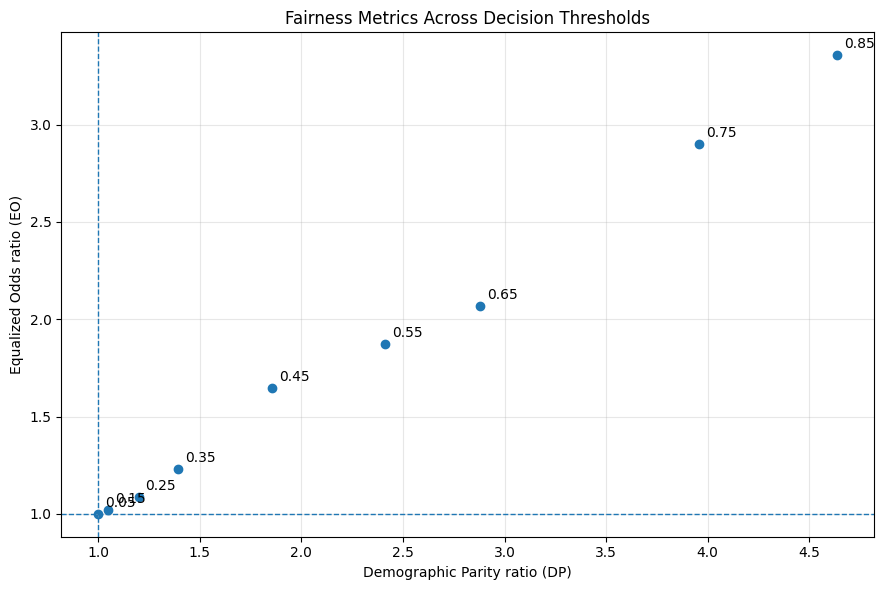

Saved: compas_fairness_thresholds.csv


In [27]:

# PART 2.4 — FAIRNESS TRADE-OFF ANALYSIS

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Use the sensitive attribute from the same test rows as the probabilities
fair_test = pd.DataFrame({
    "actual": yB_test.to_numpy(),
    "probability": np.asarray(prob_B),
    "race": data.loc[X_test.index, "race"].to_numpy()
}, index=X_test.index)

# Compare African-American (A) and Caucasian (B) groups
fair_test = fair_test[
    fair_test["race"].isin(["African-American", "Caucasian"])
].copy()

thresholds = np.round(np.arange(0.05, 1.00, 0.10), 2)

def safe_ratio(numerator, denominator):
    if (
        denominator is None
        or not np.isfinite(denominator)
        or abs(denominator) < 1e-12
        or not np.isfinite(numerator)
    ):
        return np.nan
    return numerator / denominator

def group_rates(group, threshold):
    y = group["actual"].to_numpy()
    pred = (group["probability"].to_numpy() >= threshold).astype(int)

    tp = np.sum((y == 1) & (pred == 1))
    fn = np.sum((y == 1) & (pred == 0))
    fp = np.sum((y == 0) & (pred == 1))
    tn = np.sum((y == 0) & (pred == 0))

    positive_rate = pred.mean()
    tpr = tp / (tp + fn) if (tp + fn) else np.nan
    fpr = fp / (fp + tn) if (fp + tn) else np.nan
    precision = tp / (tp + fp) if (tp + fp) else np.nan

    return positive_rate, tpr, fpr, precision

fairness_rows = []

for threshold in thresholds:
    A = fair_test[fair_test["race"] == "African-American"]
    B = fair_test[fair_test["race"] == "Caucasian"]

    dp_A, tpr_A, fpr_A, pp_A = group_rates(A, threshold)
    dp_B, tpr_B, fpr_B, pp_B = group_rates(B, threshold)

    dp_ratio = safe_ratio(dp_A, dp_B)
    tpr_ratio = safe_ratio(tpr_A, tpr_B)
    fpr_ratio = safe_ratio(fpr_A, fpr_B)
    pp_ratio = safe_ratio(pp_A, pp_B)

    # Equalized Odds metric as specified in the assignment
    eo_ratio = (
        min(tpr_ratio, fpr_ratio)
        if np.isfinite(tpr_ratio) and np.isfinite(fpr_ratio)
        else np.nan
    )

    fairness_rows.append({
        "Threshold": threshold,
        "DP Group A": dp_A,
        "DP Group B": dp_B,
        "DP ratio": dp_ratio,
        "TPR ratio": tpr_ratio,
        "FPR ratio": fpr_ratio,
        "EO ratio": eo_ratio,
        "PP Group A": pp_A,
        "PP Group B": pp_B,
        "PP ratio": pp_ratio
    })

fairness_table = pd.DataFrame(fairness_rows)

print("Fairness metrics by threshold (ideal ratio = 1):")
display(fairness_table.round(4))

# Trade-off chart: display all available threshold results
plot_df = fairness_table.dropna(
    subset=["DP ratio", "EO ratio"]
).copy()

plt.figure(figsize=(9, 6))
plt.scatter(plot_df["DP ratio"], plot_df["EO ratio"])

for _, row in plot_df.iterrows():
    plt.annotate(
        f'{row["Threshold"]:.2f}',
        (row["DP ratio"], row["EO ratio"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.axvline(1.0, linestyle="--", linewidth=1)
plt.axhline(1.0, linestyle="--", linewidth=1)
plt.xlabel("Demographic Parity ratio (DP)")
plt.ylabel("Equalized Odds ratio (EO)")
plt.title("Fairness Metrics Across Decision Thresholds")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
# Save table for the report
fairness_table.to_csv("compas_fairness_thresholds.csv", index=False)
print("Saved: compas_fairness_thresholds.csv")


### Interpreting the Fairness Trade-Off

For each threshold, calculate the absolute distance from parity:

- DP deviation = `abs(DP - 1)`
- EO deviation = `abs(EO - 1)`

A smaller deviation indicates a ratio closer to equality. The threshold sweep shows that DP and EO move in the same direction relative to their ideal value of 1.0. Therefore, the requested trade-off cost—EO loss divided by DP improvement—is not defined for a comparison that requires DP to improve while EO deteriorates.

Instead, compare the changes in DP and EO deviations alongside accuracy and predictive parity. Report the actual results without claiming that the sweep demonstrates a DP-versus-EO trade-off that it does not show.

In [28]:
# Quantify DP fairness improvement versus EO fairness deterioration

valid = fairness_table.dropna(
    subset=["DP ratio", "EO ratio"]
).copy()

valid = valid[
    (valid["DP ratio"] > 0)
    & (valid["EO ratio"] > 0)
].reset_index(drop=True)

tradeoffs = []

for _, old in valid.iterrows():
    for _, new in valid.iterrows():
        if old["Threshold"] == new["Threshold"]:
            continue

        old_dp_gap = abs(old["DP ratio"] - 1)
        new_dp_gap = abs(new["DP ratio"] - 1)

        old_eo_gap = abs(old["EO ratio"] - 1)
        new_eo_gap = abs(new["EO ratio"] - 1)

        # DP improves if its distance from parity decreases.
        if old_dp_gap > 0 and new_dp_gap < old_dp_gap:
            dp_gain = (
                (old_dp_gap - new_dp_gap) / old_dp_gap * 100
            )

            # EO deteriorates if its distance from parity increases.
            if new_eo_gap > old_eo_gap:
                eo_loss = (
                    (new_eo_gap - old_eo_gap)
                    / old_eo_gap * 100
                    if old_eo_gap > 0 else np.nan
                )

                tradeoffs.append({
                    "From threshold": old["Threshold"],
                    "To threshold": new["Threshold"],
                    "DP gap before": old_dp_gap,
                    "DP gap after": new_dp_gap,
                    "DP fairness-gap reduction (%)": dp_gain,
                    "EO gap before": old_eo_gap,
                    "EO gap after": new_eo_gap,
                    "EO fairness-gap increase (%)": eo_loss,
                    "EO loss per 1% DP-gap reduction": (
                        eo_loss / dp_gain
                        if dp_gain > 0 and np.isfinite(eo_loss)
                        else np.nan
                    )
                })

tradeoff_table = pd.DataFrame(tradeoffs)

if not tradeoff_table.empty:
    tradeoff_table = tradeoff_table.sort_values(
        "DP fairness-gap reduction (%)",
        ascending=False
    )
    display(tradeoff_table.round(4))
else:
    print(
        "No valid pair showed DP parity improving while "
        "EO parity deteriorated. Report this result."
    )

No valid pair showed DP parity improving while EO parity deteriorated. Report this result.


In [29]:

# FINAL RESULTS EXPORT — RUN AFTER ALL ANALYSIS CELLS

import os

# Create a folder for report evidence
os.makedirs("compas_report_outputs", exist_ok=True)

# Save the major result tables
simpson_results.to_csv(
    "compas_report_outputs/simpson_results.csv", index=False
)

ovb_table.to_csv(
    "compas_report_outputs/omitted_variable_bias.csv", index=False
)

adversarial_comparison.to_csv(
    "compas_report_outputs/adversarial_comparison.csv", index=False
)

adversarial_sample.to_csv(
    "compas_report_outputs/adversarial_subset.csv", index=True
)

fairness_table.to_csv(
    "compas_report_outputs/fairness_thresholds.csv", index=False
)

if not tradeoff_table.empty:
    tradeoff_table.to_csv(
        "compas_report_outputs/fairness_tradeoffs.csv",
        index=False
    )

# Save the main model-comparison results
summary = pd.DataFrame([{
    "Dataset": "COMPAS",
    "Rows after target filtering": len(data),
    "Train rows": len(X_train),
    "Test rows": len(X_test),
    "Random state": 40,
    "OLS test R-squared": model_A.score(X_test, yA_test),
    "Logistic test accuracy": accuracy_score(yB_test, pred_B),
    "OLS median prediction": median_A,
    "Mismatch count": mismatches,
    "Mismatch percentage": mismatch_percentage,
    "High-confidence errors": confident_error_count,
    "High-confidence error percentage": error_percentage
}])

summary.to_csv(
    "compas_report_outputs/model_summary.csv", index=False
)

display(summary.round(4))
print("Report evidence saved in compas_report_outputs/")


,Dataset,Rows after target filtering,Train rows,Test rows,Random state,OLS test R-squared,Logistic test accuracy,OLS median prediction,Mismatch count,Mismatch percentage,High-confidence errors,High-confidence error percentage
0,COMPAS,7214,5049,2165,40,0.4387,0.6753,4.4071,166,7.6674,97,4.4804


Report evidence saved in compas_report_outputs/


In [30]:

# REPORT EVIDENCE — THRESHOLD-SPECIFIC PERFORMANCE

threshold_performance = []

for t in thresholds:
    y_pred_t = (np.asarray(prob_B) >= t).astype(int)
    y_true = np.asarray(yB_test)

    threshold_performance.append({
        "Threshold": t,
        "Accuracy": accuracy_score(y_true, y_pred_t),
        "Predicted positive (%)": y_pred_t.mean() * 100
    })

threshold_performance = pd.DataFrame(threshold_performance)

report_metrics = fairness_table.merge(
    threshold_performance, on="Threshold", how="left"
)

display(report_metrics.round(4))

report_metrics.to_csv(
    "compas_report_outputs/all_fairness_metrics.csv",
    index=False
)


,Threshold,DP Group A,DP Group B,DP ratio,TPR ratio,FPR ratio,EO ratio,PP Group A,PP Group B,PP ratio,Accuracy,Predicted positive (%)
0,0.05,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.5615,0.4244,1.3230,0.4813,100.0000
1,0.15,0.9926,0.9478,1.0472,1.0192,1.0666,1.0192,0.5638,0.4379,1.2876,0.4979,97.3210
2,0.25,0.9534,0.7952,1.1990,1.0884,1.2840,1.0884,0.5742,0.4781,1.2010,0.5510,87.8522
3,0.35,0.8399,0.6024,1.3942,1.2288,1.4825,1.2288,0.6220,0.5333,1.1662,0.6273,72.2864
4,0.45,0.6881,0.3708,1.8556,1.6461,1.8571,1.6461,0.6779,0.5776,1.1737,0.6651,53.2564
5,0.55,0.5130,0.2129,2.4103,1.8728,2.9525,1.8728,0.7241,0.7044,1.0280,0.6697,36.0739
6,0.65,0.2970,0.1031,2.8815,2.0700,4.7052,2.0700,0.7900,0.8312,0.9504,0.6351,19.9538
7,0.75,0.1695,0.0428,3.9558,2.9011,6.0255,2.9011,0.8187,0.8438,0.9703,0.5866,10.5774
8,0.85,0.0931,0.0201,4.6369,3.3564,7.7601,3.3564,0.8300,0.8667,0.9577,0.5580,5.7737
9,0.95,0.0196,0.0040,4.8687,2.8038,NaN,NaN,0.7619,1.0000,0.7619,0.5256,1.1547


In [31]:

# Save Simpson's race-by-prior-convictions interaction results

interaction_table = pd.DataFrame(interaction_rows)

interaction_table.to_csv(
    "compas_report_outputs/simpson_interaction_results.csv",
    index=False
)

print("Saved interaction results for the report.")


Saved interaction results for the report.


In [32]:
import pandas as pd
import numpy as np

# Use the existing X_train DataFrame if it contains the
# original feature columns before pipeline transformation.
diagnostic_df = X_train.copy()

numeric_cols = diagnostic_df.select_dtypes(
    include=np.number
).columns

outlier_rows = []

for col in numeric_cols:
    series = diagnostic_df[col].dropna()

    if series.empty:
        continue

    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = ((series < lower) | (series > upper)).sum()

    outlier_rows.append({
        "Feature": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Outlier Count": int(count),
        "Outlier Percentage": round(
            100 * count / len(series), 2
        )
    })

outlier_table = pd.DataFrame(outlier_rows)

display(outlier_table)

outlier_table.to_csv(
    "compas_outlier_diagnostics.csv",
    index=False
)

print("Saved: compas_outlier_diagnostics.csv")

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,age,25.0,43.0,18.0,-2.0,70.0,21,0.42
1,juv_fel_count,0.0,0.0,0.0,0.0,0.0,196,3.88
2,juv_misd_count,0.0,0.0,0.0,0.0,0.0,285,5.64
3,juv_other_count,0.0,0.0,0.0,0.0,0.0,365,7.23
4,priors_count,0.0,5.0,5.0,-7.5,12.5,306,6.06


Saved: compas_outlier_diagnostics.csv
